In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

print("TensorFlow Version:", tf.__version__)


TensorFlow Version: 2.21.0


In [2]:
data = pd.read_csv(r"/home/pvg/Downloads/creditcard.csv")

print("Dataset Shape:", data.shape)
data.head()


FileNotFoundError: [Errno 2] No such file or directory: '/home/pvg/Downloads/creditcard.csv'

In [3]:
print(data.info())

print("\nMissing Values:")
print(data.isnull().sum())

print("\nDuplicate Rows:")
print(data.duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [4]:
data = data.drop_duplicates()

print("Dataset Shape after removing duplicates:", data.shape)


Dataset Shape after removing duplicates: (283726, 31)


In [6]:
print(data["Class"].value_counts())


Class
0    283253
1       473
Name: count, dtype: int64


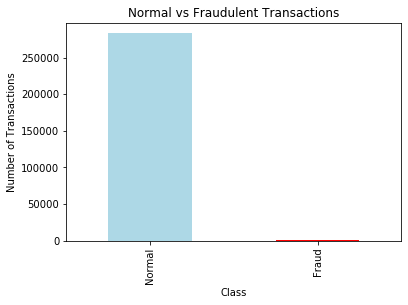

In [34]:
data["Class"].value_counts().plot(
    kind="bar",
    color=["lightblue", "red"]
)

plt.xlabel("Class")
plt.ylabel("Number of Transactions")
plt.title("Normal vs Fraudulent Transactions")
plt.xticks(
    [0, 1],
    ["Normal", "Fraud"]
)

plt.show()


In [8]:
X = data.drop("Class", axis=1)
y = data["Class"]

print("Features:", X.shape)
print("Target:", y.shape)


Features: (283726, 30)
Target: (283726,)


In [9]:
data = data.drop_duplicates()

print("Dataset shape after removing duplicates:")
print(data.shape)


Dataset shape after removing duplicates:
(283726, 31)


In [10]:
X = data.drop("Class", axis=1)
y = data["Class"]


In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)



X_train: (226980, 30)
X_test : (56746, 30)


In [13]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape :", X_test_scaled.shape)


Training data shape: (226980, 30)
Testing data shape : (56746, 30)


In [14]:
X_train_scaled = X_train_scaled.astype("float32")
X_test_scaled = X_test_scaled.astype("float32")


In [15]:
X_train_normal = X_train_scaled[
    y_train.values == 0
]

print(
    "Normal transactions used for training:",
    X_train_normal.shape
)


Normal transactions used for training: (226597, 30)


In [16]:
input_features = X_train_normal.shape[1]

autoencoder = Sequential([

    # Input layer
    Input(shape=(input_features,)),

    # Encoder
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(16, activation="relu"),
    Dense(8, activation="relu"),

    # Decoder
    Dense(16, activation="relu"),
    Dense(32, activation="relu"),
    Dense(64, activation="relu"),

    # Output layer
    Dense(input_features, activation="linear")
])

autoencoder.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 64)                1984      
                                                                 
 dense_1 (Dense)             (None, 32)                2080      
                                                                 
 dense_2 (Dense)             (None, 16)                528       
                                                                 
 dense_3 (Dense)             (None, 8)                 136       
                                                                 
 dense_4 (Dense)             (None, 16)                144       
                                                                 
 dense_5 (Dense)             (None, 32)                544       
                                                                 
 dense_6 (Dense)             (None, 64)                2

In [17]:
autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse",
    metrics=["mae"]
)

print("Autoencoder compiled successfully.")


Autoencoder compiled successfully.


In [42]:
history = autoencoder.fit(
    X_train_normal,
    X_train_normal,

    epochs=5,

    batch_size=20000,

    validation_split=0.20,

    shuffle=True,

    verbose=1
)


Epoch 1/5
10/10 [==============================] - 0s 40ms/step - loss: 0.1797 - mae: 0.2754 - val_loss: 0.1877 - val_mae: 0.2781
Epoch 2/5
10/10 [==============================] - 0s 32ms/step - loss: 0.1798 - mae: 0.2755 - val_loss: 0.1878 - val_mae: 0.2788
Epoch 3/5
10/10 [==============================] - 0s 30ms/step - loss: 0.1798 - mae: 0.2756 - val_loss: 0.1877 - val_mae: 0.2781
Epoch 4/5
10/10 [==============================] - 0s 33ms/step - loss: 0.1798 - mae: 0.2756 - val_loss: 0.1876 - val_mae: 0.2779
Epoch 5/5
10/10 [==============================] - 0s 32ms/step - loss: 0.1797 - mae: 0.2754 - val_loss: 0.1876 - val_mae: 0.2778


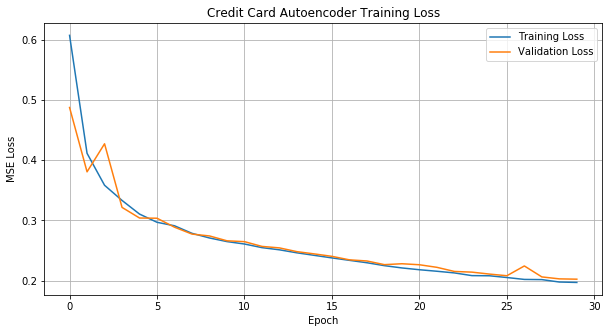

In [19]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.title(
    "Credit Card Autoencoder Training Loss"
)

plt.legend()
plt.grid()

plt.show()


In [20]:
X_train_reconstructed = autoencoder.predict(
    X_train_normal,
    batch_size=256,
    verbose=0
)

print(
    "Original shape:",
    X_train_normal.shape
)

print(
    "Reconstructed shape:",
    X_train_reconstructed.shape
)


Original shape: (226597, 30)
Reconstructed shape: (226597, 30)


In [21]:
normal_error = np.mean(
    np.square(
        X_train_normal -
        X_train_reconstructed
    ),
    axis=1
)

print("Normal reconstruction error:")
print(normal_error[:10])


Normal reconstruction error:
[0.33645555 0.12606473 0.0430791  0.13514468 0.28265592 0.47146043
 0.09430704 0.12436326 0.11644283 0.25181755]


In [22]:
threshold = np.percentile(
    normal_error,
    95
)

print(
    "Anomaly Threshold:",
    threshold
)


Anomaly Threshold: 0.642250609397888


In [23]:
X_test_reconstructed = autoencoder.predict(
    X_test_scaled,
    batch_size=256,
    verbose=0
)

print(
    "Test reconstructed shape:",
    X_test_reconstructed.shape
)


Test reconstructed shape: (56746, 30)


In [24]:
test_error = np.mean(
    np.square(
        X_test_scaled -
        X_test_reconstructed
    ),
    axis=1
)

print("First 10 test errors:")
print(test_error[:10])


First 10 test errors:
[0.05976238 0.12165207 0.20761506 0.15576135 0.3960789  0.06830447
 0.38333496 0.03054093 0.22426333 0.07663154]


In [25]:
y_pred = (
    test_error > threshold
).astype(int)

print("Predicted classes:")
print(y_pred[:20])


Predicted classes:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [26]:
results = pd.DataFrame({
    "Actual_Class": y_test.values,
    "Reconstruction_Error": test_error,
    "Predicted_Class": y_pred
})

results.head(20)


,Actual_Class,Reconstruction_Error,Predicted_Class
0,0,0.059762,0
1,0,0.121652,0
2,0,0.207615,0
3,0,0.155761,0
4,0,0.396079,0
5,0,0.068304,0
6,0,0.383335,0
7,0,0.030541,0
8,0,0.224263,0
9,0,0.076632,0


In [27]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

print("Accuracy:", accuracy)


Accuracy: 0.9491241673421915


In [28]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print(cm)


[[53782  2874]
 [   13    77]]


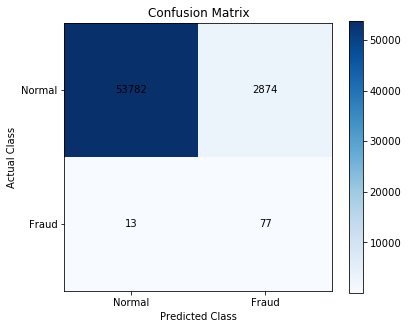

In [29]:
plt.figure(figsize=(6, 5))

plt.imshow(
    cm,
    cmap="Blues"
)

plt.colorbar()

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.title("Confusion Matrix")

plt.xticks(
    [0, 1],
    ["Normal", "Fraud"]
)

plt.yticks(
    [0, 1],
    ["Normal", "Fraud"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.show()


In [ ]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Normal",
            "Fraud" 
        ]
    )
)


              precision    recall  f1-score   support

      Normal       1.00      0.95      0.97     56656
       Fraud       0.03      0.86      0.05        90

    accuracy                           0.95     56746
   macro avg       0.51      0.90      0.51     56746
weighted avg       1.00      0.95      0.97     56746



In [32]:
fraud_transactions = results[
    results["Predicted_Class"] == 1
]

print(
    "Number of detected anomalies:",
    len(fraud_transactions)
)

fraud_transactions.head(20)


Number of detected anomalies: 2951


,Actual_Class,Reconstruction_Error,Predicted_Class
27,0,1.085631,1
35,0,1.567804,1
44,0,0.989552,1
47,0,0.701752,1
80,0,0.655887,1
84,0,0.679162,1
95,0,0.770477,1
117,0,0.892503,1
128,0,0.799935,1
141,0,2.641196,1
